# 05 -- Megadrought Analysis: Chilean Glacier Melt and Streamflow

Investigates how the Chilean Megadrought affected glacier melt
contributions to streamflow across Chile's latitudinal gradient.

**This version loads all THREE basin definitions (`all_glacierized`,
`grouped_main`, `leaf_only`) up front and loops the core drought metrics
(amplification, decomposition, trend significance) across all three
basin sets x all three climate datasets (CR2MET, ERA5, CRU) -- 9
combinations total -- rather than requiring a manual `BASIN_SET` switch
and rerun.**

**Design note on Sections II/III/VI (climate validation, snow drought,
climate drivers):** these characterize the CAMELS-CL/OGGM climate
forcing itself (precipitation, temperature, snowfall) at the cluster
level, not modeled glacier melt or streamflow -- so they don't depend on
which basin population is used downstream. They're computed ONCE, using
the broadest basin set (`all_glacierized`) to define which gauges
represent each cluster, since it has the most stations per cluster to
average over. Sections IV, V, and the verification pass -- which DO
depend on basin choice -- loop over all three basin sets explicitly.

**Recession/aridity analysis (Becca), lag/routing analysis, long-term
melt and mass-balance trends (Noah), the seasonal-definition question,
and methods-draft statistics (Ale) continue in
`06_megadrought_extensions.ipynb`.**

## Sections
0. Load all three basin sets
I. Load CAMELS-CL climate
II. Empirical validation of drought period definitions
III. Snow drought diagnosis (OGGM-based)
IV. Glacier melt during drought -- amplification (basin-set x dataset loop)
V. Decomposition: Q-decline vs. melt-change (basin-set x dataset loop)
VI. Climate driver analysis
VII. Chile map + basin-set comparison figure
VIII. Summary of findings
Verification pass: re-checking headline claims across all 9 combinations


## Cell 0: Imports, paths, and loading all three basin sets

In [1]:
import os, sys, pickle, calendar, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
warnings.filterwarnings('ignore')

sys.path.insert(0, '/Users/milliespencer/OGGM_CR2_Chile')
from basin_hierarchy_utils import compute_basin_hierarchy, build_containment_maps
from completeness_utils import assess_completeness

BASE_PATH    = '/Users/milliespencer/Desktop/CR2_OGGM_Paper'
OUTPUT_ROOT  = f'{BASE_PATH}/Output'
CAMELS_FULL  = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
RGI_PATH     = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'
BOUNDS_PATH  = f'{CAMELS_FULL}/camels_cl_boundaries/camels_cl_boundaries.shp'
OUT_DIR_SUB  = f'{OUTPUT_ROOT}/all_chile_results_v2'
OUT_DIR_GRP  = f'{OUTPUT_ROOT}/grouped_basin_results'
OUT_DIR      = OUT_DIR_SUB   # legacy alias for a few cells below

DROUGHT_DIR = f'{OUTPUT_ROOT}/megadrought_analysis/all_basin_sets'
os.makedirs(DROUGHT_DIR, exist_ok=True)

YEARS         = list(range(2000, 2020))
MONTHS        = list(range(1, 13))
YEAR_OFFSET   = 1
WATER_DENSITY = 1000
CLUSTERS      = ['OT3','DA1','DA2','DA3','WA1','WA2','WA3','WA4','WA5','WA6']
DATASETS      = {'CR2MET': 'TC', 'ERA5': 'ERA5', 'CRU': 'CRU'}
DS_COLORS     = {'CR2MET': '#1f77b4', 'ERA5': '#ff7f0e', 'CRU': '#2ca02c'}
REGION_LABELS = {
    'OT3': 'Altiplano',     'DA1': 'Dry Andes N',
    'DA2': 'Dry Andes C',   'DA3': 'Dry Andes S',
    'WA1': 'Wet Andes N',   'WA2': 'Wet Andes C',
    'WA3': 'N Patagonia',   'WA4': 'S Patagonia',
    'WA5': 'Patagonia',     'WA6': 'Tierra del Fuego',
}
BASELINE     = list(range(2000, 2010))
DROUGHT_DEFS = {
    'Baseline (2000-2009)':  list(range(2000, 2010)),
    'Drought 1 (2010-2019)': list(range(2010, 2020)),
    'Drought 2 (2013-2019)': list(range(2013, 2020)),
    'Drought 3 (2015-2019)': list(range(2015, 2020)),
}
DROUGHT_COLORS = {
    'Baseline (2000-2009)':  '#2ecc71',
    'Drought 1 (2010-2019)': '#f39c12',
    'Drought 2 (2013-2019)': '#e67e22',
    'Drought 3 (2015-2019)': '#c0392b',
}
SUMMER = [12, 1, 2]
WINTER = [6, 7, 8]
CENTRAL_ANDES = ['DA1','DA2','DA3']
BASIN_SET_NAMES = ['all_glacierized', 'grouped_main', 'leaf_only']

def nc_path(dataset_name, cluster):
    tag = DATASETS[dataset_name]
    return (f'{OUTPUT_ROOT}/{dataset_name}/{cluster}/'
            f'run_output_2000_2019_hydro_{tag}_{cluster}.nc')


# -- load_basin_set(): identical logic to 04_regression_analysis.ipynb
# and basin_set_comparison.ipynb, so all basin-set definitions stay
# consistent across notebooks.

def _load_q_day():
    q_day = pd.read_csv(f'{CAMELS_FULL}/q_m3s_day.csv', parse_dates=['date'])
    return q_day[(q_day['year'] >= 1999) & (q_day['year'] <= 2019)].copy()

def _gauge_info_from_nested(nested_csv):
    info = {}
    for gauge_id, grp in nested_csv.groupby('gauge_id'):
        info[gauge_id] = {
            'gauge_name':       grp['gauge_name'].iloc[0],
            'rgi_ids':          grp['RGIId'].tolist(),
            'n_glaciers':       len(grp),
            'glacier_area_km2': grp['Area'].sum(),
            'basin_area_km2':   grp['area_km2'].iloc[0],
            'clusters':         sorted(grp['Cluster'].unique().tolist()),
            'cen_lat':          grp['CenLat'].mean(),
            'cen_lon':          grp['CenLon'].mean(),
        }
    return info

def load_basin_set(basin_set):
    if basin_set == 'all_glacierized':
        with open(f'{OUT_DIR_SUB}/RESULTS.pkl', 'rb') as f:
            RESULTS = pickle.load(f)
        nested_csv = pd.read_csv(f'{OUT_DIR_SUB}/spatial_join_nested.csv', dtype={'gauge_id': str})
        GAUGE_INFO = _gauge_info_from_nested(nested_csv)

        q_day = _load_q_day()
        gauges_in_results = set(RESULTS['CR2MET'].keys())
        GAUGE_INFO_FRAC = {}
        for gid, info in GAUGE_INFO.items():
            if gid not in gauges_in_results:
                continue
            comp = assess_completeness(q_day, gid, info['cen_lat'])
            if comp['passes']:
                GAUGE_INFO_FRAC[gid] = {**info, 'complete_years': comp['complete_years']}

        label = f'All glacierized sub-basins (nested, n={len(GAUGE_INFO_FRAC)})'

    elif basin_set == 'grouped_main':
        with open(f'{OUT_DIR_GRP}/RESULTS_grouped.pkl', 'rb') as f:
            RESULTS = pickle.load(f)

        GAUGE_INFO_FRAC = {}
        for gid, res in RESULTS['CR2MET'].items():
            if res is None:
                continue
            GAUGE_INFO_FRAC[gid] = {
                'gauge_name':       res['gauge_name'],
                'clusters':         res['clusters'],
                'cen_lat':          res['cen_lat'],
                'glacier_area_km2': res['glacier_area_km2'],
                'basin_area_km2':   res['basin_area_km2'],
                'complete_years':   res['complete_years'],
                'rgi_ids':          [],
            }

        label = f'Geometrically top-level "main" basins (depth=0, n={len(GAUGE_INFO_FRAC)})'

    elif basin_set == 'leaf_only':
        with open(f'{OUT_DIR_SUB}/RESULTS.pkl', 'rb') as f:
            RESULTS = pickle.load(f)
        nested_csv = pd.read_csv(f'{OUT_DIR_SUB}/spatial_join_nested.csv', dtype={'gauge_id': str})
        GAUGE_INFO = _gauge_info_from_nested(nested_csv)
        glacier_area_by_gauge = nested_csv.groupby('gauge_id')['Area'].sum().to_dict()
        all_glacierized_ids = set(gid for gid, area in glacier_area_by_gauge.items() if area > 0)

        bounds_all = gpd.read_file(BOUNDS_PATH).to_crs(epsg=4326)
        bounds_all['gauge_id'] = bounds_all['gauge_id'].astype(str)
        bounds_utm = bounds_all.to_crs(epsg=32719)
        contained_map, container_map = build_containment_maps(bounds_utm, candidate_ids=all_glacierized_ids)

        leaf_ids = set()
        for gid in all_glacierized_ids:
            glacierized_children = [c for c in contained_map.get(gid, [])
                                     if glacier_area_by_gauge.get(c, 0) > 0]
            if len(glacierized_children) == 0:
                leaf_ids.add(gid)

        q_day = _load_q_day()
        gauges_in_results = set(RESULTS['CR2MET'].keys())
        GAUGE_INFO_FRAC = {}
        for gid in leaf_ids:
            if gid not in GAUGE_INFO or gid not in gauges_in_results:
                continue
            info = GAUGE_INFO[gid]
            comp = assess_completeness(q_day, gid, info['cen_lat'])
            if comp['passes']:
                GAUGE_INFO_FRAC[gid] = {**info, 'complete_years': comp['complete_years']}

        label = f'Leaf-level glacierized sub-basins (n={len(GAUGE_INFO_FRAC)} of {len(leaf_ids)} total leaves)'

    else:
        raise ValueError(f'Unknown basin_set: {basin_set!r}')

    return RESULTS, GAUGE_INFO_FRAC, label


BASIN_SETS = {}
for bs in BASIN_SET_NAMES:
    print(f'Loading {bs}...')
    RESULTS_bs, GAUGE_INFO_FRAC_bs, label = load_basin_set(bs)
    BASIN_SETS[bs] = {'RESULTS': RESULTS_bs, 'GAUGE_INFO_FRAC': GAUGE_INFO_FRAC_bs, 'label': label}
    print(f'  {label}')

# For Sections II/III/VI (climate-forcing characterization, not basin-set
# dependent) and any legacy cell expecting a single active RESULTS /
# GAUGE_INFO_FRAC, default to the broadest set (all_glacierized).
RESULTS         = BASIN_SETS['all_glacierized']['RESULTS']
GAUGE_INFO_FRAC = BASIN_SETS['all_glacierized']['GAUGE_INFO_FRAC']
BASIN_SET       = 'all_glacierized'
BASIN_SET_LABEL = BASIN_SETS['all_glacierized']['label']

print()
print('All three basin sets loaded. Cell 0 complete.')
print(f'  all_glacierized: n={len(BASIN_SETS["all_glacierized"]["GAUGE_INFO_FRAC"])}')
print(f'  grouped_main:    n={len(BASIN_SETS["grouped_main"]["GAUGE_INFO_FRAC"])}')
print(f'  leaf_only:       n={len(BASIN_SETS["leaf_only"]["GAUGE_INFO_FRAC"])}')


Loading all_glacierized...
  All glacierized sub-basins (nested, n=143)
Loading grouped_main...
  Geometrically top-level "main" basins (depth=0, n=33)
Loading leaf_only...
  Leaf-level glacierized sub-basins (n=54 of 103 total leaves)

All three basin sets loaded. Cell 0 complete.
  all_glacierized: n=143
  grouped_main:    n=33
  leaf_only:       n=54


## I. Load CAMELS-CL basin-average climate data

Basin-average monthly precipitation, temperature, and PET from
CAMELS-CL (CR2MET). Used to empirically validate drought period
definitions and diagnose drought drivers -- independent of basin-set
choice (covers all 516 national CAMELS gauges).

In [2]:
print('Loading CAMELS-CL climate...')

def load_camels_mon(fname, year_range=(2000,2019)):
    df = pd.read_csv(f'{CAMELS_FULL}/{fname}')
    df = df[(df['year'] >= year_range[0]) & (df['year'] <= year_range[1])].copy()
    gauge_cols = [c for c in df.columns if c not in ['date','year','month','day']]
    return df[['year','month'] + gauge_cols]

precip_df = load_camels_mon('precip_cr2met_mm_mon.csv')
tmean_df  = load_camels_mon('tmean_cr2met_C_mon.csv')
pet_df    = load_camels_mon('pet_hargreaves_mm_mon.csv')

print(f'Precip: {precip_df.shape}  Tmean: {tmean_df.shape}  PET: {pet_df.shape}')


Loading CAMELS-CL climate...
Precip: (240, 518)  Tmean: (240, 519)  PET: (240, 518)


## II. Empirical validation of drought period definitions

Confirms the three drought period definitions correspond to real
precipitation deficits, using basin-average CR2MET annual/seasonal
anomalies vs. the 2000-2009 baseline. Computed once using the
`all_glacierized` gauge set (broadest per-cluster station sample) --
see design note at the top of this notebook.

Computing annual climate aggregations...
  WA5: no gauges found -- skipping
Climate DataFrame built: (180, 6)

Annual precipitation anomaly vs 2000-2009 baseline (%) by period:
Cluster  Drought 1 (2010-2019)   Drought 2 (2013-2019)   Drought 3 (2015-2019) 
--------------------------------------------------------------------------------
OT3     -1.3%                    -5.1%                    -1.5%                  
DA1     -2.9%                    +2.1%                    +16.4%                  
DA2     -40.6%                    -38.1%                    -36.9%                  
DA3     -29.6%                    -28.7%                    -28.1%                  
WA1     -16.6%                    -15.9%                    -17.2%                  
WA2     -5.0%                    -5.5%                    -7.5%                  
WA3     +9.5%                    +9.4%                    +8.4%                  
WA4     +6.7%                    +5.6%                    +4.4%               

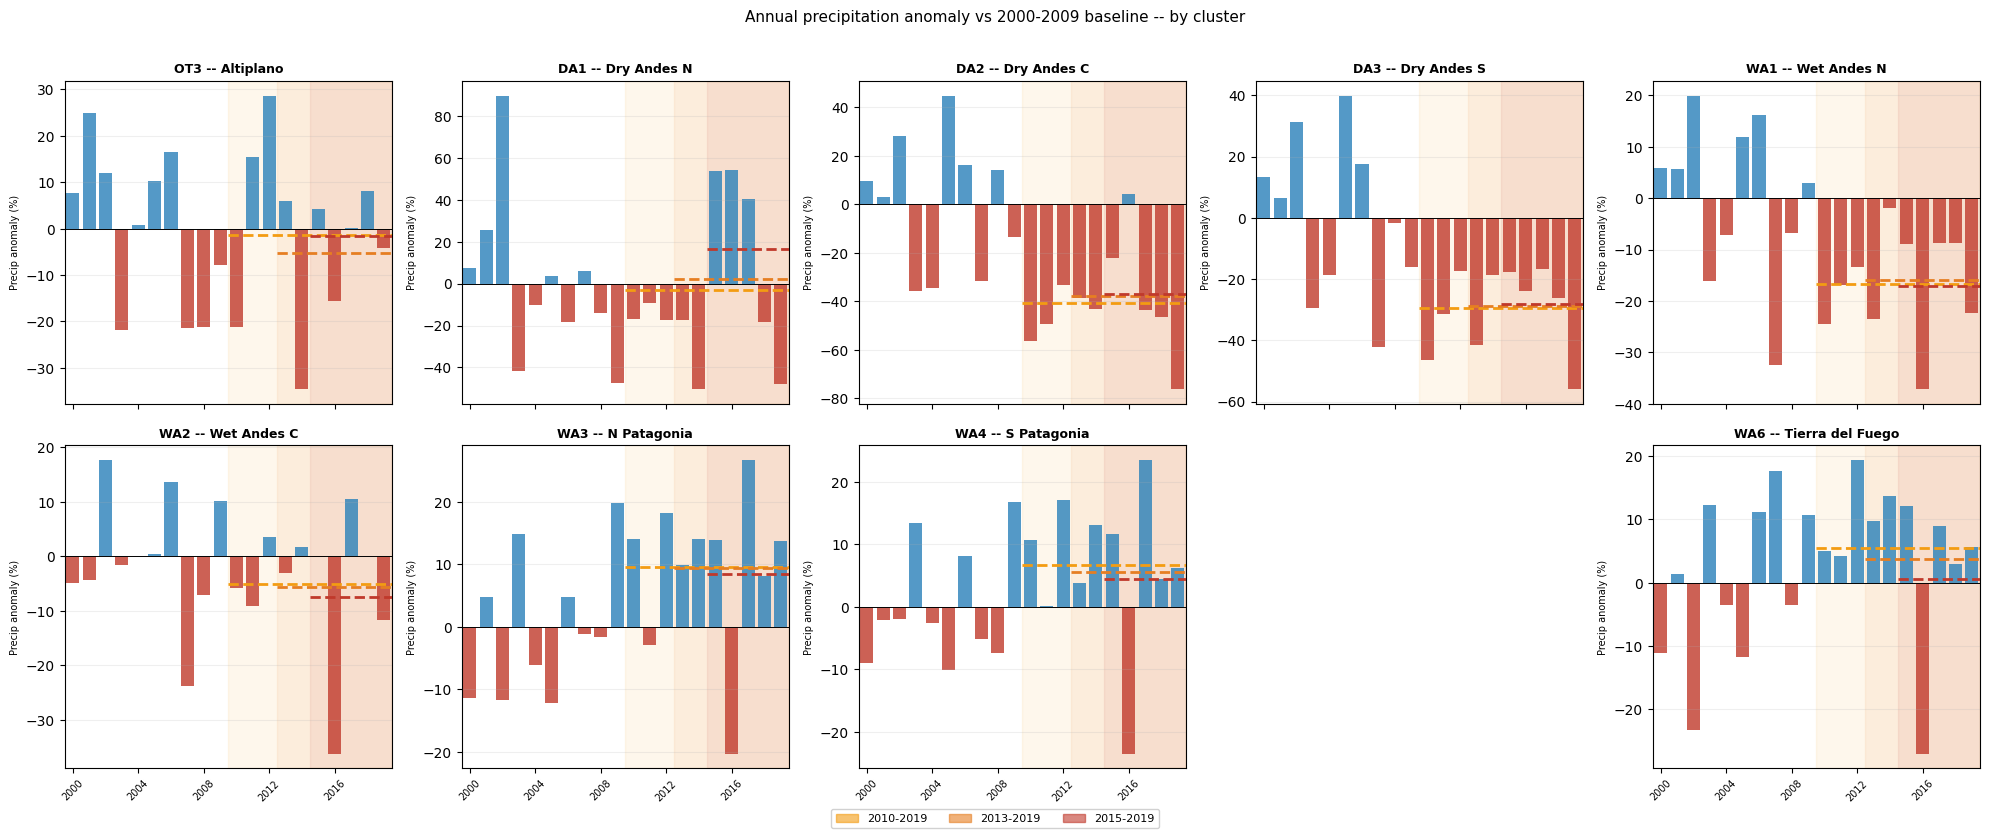

In [3]:
NON_GAUGE = ['date', 'year', 'month', 'day']

cluster_gauges = {cl: [gid for gid, info in GAUGE_INFO_FRAC.items() if info['clusters'][0] == cl]
                  for cl in CLUSTERS}

print('Computing annual climate aggregations...')

def season_agg(df, months, agg='sum'):
    gauge_cols = [c for c in df.columns if c not in NON_GAUGE]
    sub = df[df['month'].isin(months)][['year'] + gauge_cols]
    if agg == 'sum':
        return sub.groupby('year')[gauge_cols].sum(numeric_only=True)
    return sub.groupby('year')[gauge_cols].mean(numeric_only=True)

ann_precip = season_agg(precip_df, list(range(1,13)), 'sum')
win_precip = season_agg(precip_df, WINTER, 'sum')
ann_tmean  = season_agg(tmean_df, list(range(1,13)), 'mean')
ann_pet    = season_agg(pet_df, list(range(1,13)), 'sum')

clim_records = []
for cl in CLUSTERS:
    gauges = [g for g in cluster_gauges[cl] if g in ann_precip.columns]
    if not gauges:
        print(f'  {cl}: no gauges found -- skipping')
        continue
    for year in YEARS:
        def get_val(df_wide, yr):
            if yr not in df_wide.index:
                return np.nan
            cols = [g for g in gauges if g in df_wide.columns]
            return df_wide.loc[yr, cols].mean() if cols else np.nan

        clim_records.append({
            'cluster': cl, 'year': year,
            'precip_ann': get_val(ann_precip, year), 'precip_win': get_val(win_precip, year),
            'tmean_ann': get_val(ann_tmean, year), 'pet_ann': get_val(ann_pet, year),
        })

df_clim = pd.DataFrame(clim_records)
print(f'Climate DataFrame built: {df_clim.shape}')

baseline_means = (df_clim[df_clim['year'].isin(BASELINE)].groupby('cluster')[
    ['precip_ann','precip_win','tmean_ann','pet_ann']].mean().rename(columns=lambda c: c + '_base'))

df_clim = df_clim.merge(baseline_means, on='cluster', how='left')
df_clim['precip_ann_anom_pct'] = ((df_clim['precip_ann'] - df_clim['precip_ann_base']) / df_clim['precip_ann_base'] * 100)
df_clim['precip_win_anom_pct'] = ((df_clim['precip_win'] - df_clim['precip_win_base']) / df_clim['precip_win_base'] * 100)
df_clim['tmean_anom']          = (df_clim['tmean_ann'] - df_clim['tmean_ann_base'])
df_clim['pet_anom_pct']        = ((df_clim['pet_ann'] - df_clim['pet_ann_base']) / df_clim['pet_ann_base'] * 100)

print()
print('Annual precipitation anomaly vs 2000-2009 baseline (%) by period:')
print(f'{"Cluster":6s}', end='')
for period_label in list(DROUGHT_DEFS.keys())[1:]:
    print(f'  {period_label:22s}', end='')
print()
print('-' * 80)

for cl in CLUSTERS:
    cl_df = df_clim[df_clim['cluster'] == cl]
    if len(cl_df) == 0:
        continue
    print(f'{cl:6s}', end='')
    for period_label, years in list(DROUGHT_DEFS.items())[1:]:
        anom = cl_df[cl_df['year'].isin(years)]['precip_ann_anom_pct'].mean()
        print(f'  {anom:+.1f}%{" "*18}', end='')
    print()

fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True)
axes_flat = axes.flatten()

for ax, cl in zip(axes_flat, CLUSTERS):
    cl_df = df_clim[df_clim['cluster'] == cl].set_index('year')
    if len(cl_df) == 0:
        ax.set_visible(False)
        continue
    colors = ['#c0392b' if v < 0 else '#2980b9' for v in cl_df['precip_ann_anom_pct']]
    ax.bar(cl_df.index, cl_df['precip_ann_anom_pct'], color=colors, alpha=0.8, edgecolor='none')
    ax.axhline(0, color='k', lw=0.7)
    for period_label, years in list(DROUGHT_DEFS.items())[1:]:
        ax.axvspan(min(years)-0.5, max(years)+0.5, color=DROUGHT_COLORS[period_label], alpha=0.08, zorder=0)
        mean_anom = cl_df.loc[cl_df.index.isin(years), 'precip_ann_anom_pct'].mean()
        if not np.isnan(mean_anom):
            ax.hlines(mean_anom, min(years)-0.5, max(years)+0.5, color=DROUGHT_COLORS[period_label], lw=2, ls='--', zorder=5)
    ax.set_title(f'{cl} -- {REGION_LABELS[cl]}', fontsize=9, fontweight='bold')
    ax.set_ylabel('Precip anomaly (%)', fontsize=7)
    ax.set_xlim(1999.5, 2019.5); ax.set_xticks(range(2000, 2020, 4))
    ax.tick_params(labelsize=7, axis='x', rotation=45)
    ax.grid(True, alpha=0.2, axis='y')

fig.legend(handles=[
    Patch(color=DROUGHT_COLORS['Drought 1 (2010-2019)'], alpha=0.6, label='2010-2019'),
    Patch(color=DROUGHT_COLORS['Drought 2 (2013-2019)'], alpha=0.6, label='2013-2019'),
    Patch(color=DROUGHT_COLORS['Drought 3 (2015-2019)'], alpha=0.6, label='2015-2019'),
], loc='lower center', ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.02), framealpha=0.9)

fig.suptitle('Annual precipitation anomaly vs 2000-2009 baseline -- by cluster', fontsize=11, y=1.01)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/precip_anomaly_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()


## III. Snow drought diagnosis (OGGM-based)

Uses OGGM's `snowfall_on_glacier_monthly` (actual simulated solid
precipitation at glacier elevation) rather than a basin-average
precip x fixed snow-fraction proxy. Framework follows Harpold et al.
(2017). Computed once (cluster/glacier level, not basin-set dependent).

In [4]:
print('Loading OGGM snowfall on glacier for all clusters...')

import xarray as xr

snowfall_records = []

for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    for cl in CLUSTERS:
        path = nc_path(ds_name, cl)
        if not os.path.exists(path):
            continue
        try:
            ds = xr.open_dataset(path)
            if 'snowfall_on_glacier_monthly' not in ds:
                continue
            snow = ds['snowfall_on_glacier_monthly'].values
            annual_snow = np.nansum(np.nansum(snow, axis=1), axis=-1)
            for i, year in enumerate(range(2000, 2020)):
                snowfall_records.append({'dataset': ds_name, 'cluster': cl, 'year': year,
                                         'snowfall_kg': annual_snow[i + YEAR_OFFSET]})
            ds.close()
        except Exception as e:
            print(f'  Error {ds_name} {cl}: {e}')

df_snowfall = pd.DataFrame(snowfall_records)
print(f'Snowfall records: {len(df_snowfall):,}')

print()
print('Snow drought classification -- Harpold et al. (2017) framework')
print(f'{"Cluster":6s} {"Dataset":8s} {"Period":25s} {"Snow anom%":11s} {"P anom%":8s} {"T anom C":9s} {"Classification"}')
print('-' * 90)

snow_drought_records = []

for ds_name in ['CR2MET', 'ERA5', 'CRU']:
    for cl in CLUSTERS:
        cl_snow = df_snowfall[(df_snowfall['dataset'] == ds_name) & (df_snowfall['cluster'] == cl)]
        if len(cl_snow) == 0:
            continue
        cl_clim = df_clim[df_clim['cluster'] == cl]
        snow_ts = cl_snow.set_index('year')['snowfall_kg']
        snow_base = snow_ts[snow_ts.index.isin(BASELINE)].mean()

        for period_label, years in list(DROUGHT_DEFS.items())[1:]:
            snow_drought = snow_ts[snow_ts.index.isin(years)].mean()
            snow_anom = ((snow_drought - snow_base) / snow_base * 100) if snow_base > 0 else np.nan
            winp_anom = (cl_clim[cl_clim['year'].isin(years)]['precip_win_anom_pct'].mean())
            temp_anom = (cl_clim[cl_clim['year'].isin(years)]['tmean_anom'].mean())

            snow_below, prec_below, temp_warm = snow_anom < -10, winp_anom < -15, temp_anom > 0.3

            if not snow_below:
                dtype = 'No snow drought'
            elif prec_below and temp_warm:
                dtype = 'Compound (dry + warm)'
            elif prec_below:
                dtype = 'Dry snow drought'
            elif temp_warm:
                dtype = 'Warm snow drought'
            else:
                dtype = 'Dry snow drought'

            print(f'{cl:6s} {ds_name:8s} {period_label:25s} {snow_anom:+11.1f}% {winp_anom:+8.1f}% {temp_anom:+9.2f}C {dtype}')
            snow_drought_records.append({'cluster': cl, 'dataset': ds_name, 'period': period_label,
                                         'snow_anom': snow_anom, 'winp_anom': winp_anom, 'temp_anom': temp_anom, 'dtype': dtype})
        print()

df_snow_drought = pd.DataFrame(snow_drought_records)

print('Consensus classification (majority vote across 3 datasets):')
for cl in CLUSTERS:
    for period_label in list(DROUGHT_DEFS.keys())[1:]:
        sub = df_snow_drought[(df_snow_drought['cluster'] == cl) & (df_snow_drought['period'] == period_label)]
        if len(sub) == 0:
            continue
        votes = sub['dtype'].value_counts()
        print(f'{cl:6s} {period_label:25s} {votes.index[0]} ({votes.iloc[0]}/3 datasets)')


Loading OGGM snowfall on glacier for all clusters...
Snowfall records: 600

Snow drought classification -- Harpold et al. (2017) framework
Cluster Dataset  Period                    Snow anom%  P anom%  T anom C  Classification
------------------------------------------------------------------------------------------
OT3    CR2MET   Drought 1 (2010-2019)            -8.3%    -13.8%     +0.21C No snow drought
OT3    CR2MET   Drought 2 (2013-2019)           -11.2%     +8.8%     +0.21C Dry snow drought
OT3    CR2MET   Drought 3 (2015-2019)           -11.1%     -1.1%     +0.31C Warm snow drought

DA1    CR2MET   Drought 1 (2010-2019)            -3.2%    -25.4%     +0.15C No snow drought
DA1    CR2MET   Drought 2 (2013-2019)            +3.3%    -19.8%     +0.27C No snow drought
DA1    CR2MET   Drought 3 (2015-2019)           +12.0%     -1.4%     +0.39C No snow drought

DA2    CR2MET   Drought 1 (2010-2019)           -44.9%    -55.5%     +0.07C Dry snow drought
DA2    CR2MET   Drought 2 (2013

## IV. Glacier melt during drought -- amplification (basin-set x dataset loop)

For each basin, drought period, dataset, AND basin set: mean annual
glacier runoff, mean annual Q, glacier fraction, and drought
amplification factor. Looped across all 3 basin sets x 3 datasets = 9
combinations, so the sensitivity of the amplification result to both
choices is visible directly, rather than requiring a separate notebook
run per combination.

In [5]:
print('Computing period means for all basins, across all basin sets and datasets...')

period_records = []

for bs_name, bs_data in BASIN_SETS.items():
    RESULTS_bs, GAUGE_INFO_FRAC_bs = bs_data['RESULTS'], bs_data['GAUGE_INFO_FRAC']

    for gauge_id, info in GAUGE_INFO_FRAC_bs.items():
        cy = info['complete_years']

        for ds_name in ['CR2MET', 'ERA5', 'CRU']:
            res = RESULTS_bs[ds_name].get(gauge_id)
            if res is None:
                continue
            m = res['monthly']

            for period_label, years in DROUGHT_DEFS.items():
                valid_years = [y for y in years if y in cy]
                if len(valid_years) < 2:
                    continue

                period_m = m[m['year'].isin(valid_years)]
                ann = period_m.groupby('year').agg(
                    glac_m3=('glacier_runoff_m3', 'sum'), q_m3=('q_m3_mon', 'sum'))
                ann = ann[ann['q_m3'] > 0]
                if len(ann) == 0:
                    continue

                period_records.append({
                    'basin_set': bs_name, 'gauge_id': gauge_id,
                    'cluster': info['clusters'][0] if info.get('clusters') else 'unknown',
                    'dataset': ds_name, 'period': period_label, 'n_years': len(ann),
                    'glac_km3yr': ann['glac_m3'].mean() / 1e9,
                    'q_km3yr':    ann['q_m3'].mean()    / 1e9,
                    'frac_mean':  (ann['glac_m3'] / ann['q_m3']).mean(),
                })

df_periods_all = pd.DataFrame(period_records)
print(f'Period records across all basin sets: {len(df_periods_all):,}')

baseline_fracs = (df_periods_all[df_periods_all['period'] == 'Baseline (2000-2009)']
                  [['basin_set','gauge_id','dataset','frac_mean','glac_km3yr','q_km3yr']]
                  .rename(columns={'frac_mean': 'frac_base', 'glac_km3yr': 'glac_base', 'q_km3yr': 'q_base'}))

df_periods_all = df_periods_all.merge(baseline_fracs, on=['basin_set','gauge_id','dataset'], how='left')
df_periods_all['amp_factor'] = (df_periods_all['frac_mean'] / df_periods_all['frac_base'])

df_periods_all.to_csv(f'{DROUGHT_DIR}/period_means_all_basin_sets.csv', index=False)
print(f'Saved: {DROUGHT_DIR}/period_means_all_basin_sets.csv')

print()
print('National median amplification factor (Drought 1: 2010-2019 vs baseline),')
print('by basin set and dataset:')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_periods_all[
            (df_periods_all['basin_set'] == bs_name) & (df_periods_all['dataset'] == ds_name) &
            (df_periods_all['period'] == 'Drought 1 (2010-2019)') &
            (df_periods_all['amp_factor'].notna()) & (df_periods_all['amp_factor'] < 10)]
        med = sub['amp_factor'].median() if len(sub) else np.nan
        row += f' {med:9.2f}x'
    print(row)

print()
print('Central Andes (DA1+DA2+DA3) median amplification factor, by basin set and dataset:')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_periods_all[
            (df_periods_all['basin_set'] == bs_name) & (df_periods_all['dataset'] == ds_name) &
            (df_periods_all['period'] == 'Drought 1 (2010-2019)') &
            (df_periods_all['cluster'].isin(CENTRAL_ANDES)) &
            (df_periods_all['amp_factor'].notna()) & (df_periods_all['amp_factor'] < 10)]
        med = sub['amp_factor'].median() if len(sub) else np.nan
        row += f' {med:9.2f}x'
    print(row)

# Convenience alias: df_periods for 'all_glacierized' + CR2MET-only legacy
# cells elsewhere in this notebook (e.g. the single-map cell in Section VII).
df_periods = df_periods_all[df_periods_all['basin_set'] == 'all_glacierized'].copy()


Computing period means for all basins, across all basin sets and datasets...
Period records across all basin sets: 2,643
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/megadrought_analysis/all_basin_sets/period_means_all_basin_sets.csv

National median amplification factor (Drought 1: 2010-2019 vs baseline),
by basin set and dataset:
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized         1.57x      1.61x      1.59x
grouped_main            1.35x      1.45x      1.39x
leaf_only               1.37x      1.46x      1.42x

Central Andes (DA1+DA2+DA3) median amplification factor, by basin set and dataset:
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized         2.25x      2.40x      2.38x
grouped_main            2.12x      1.90x      2.21x
leaf_only               2.12x      2.32x      2.10x


## V. Decomposing the drought amplification signal (basin-set x dataset loop)

Decomposes the increase in glacier fraction during drought (Drought 1:
2010-2019 vs. baseline) into Q-decline vs. melt-increase using a
counterfactual approach, across all 3 basin sets x 3 datasets.

In [6]:
# ── V. Decomposing the drought amplification signal (basin-set x dataset loop) ──
# CORRECTED: reuses df_periods_all's frac_mean (mean of per-year ratios)
# for the actual baseline/drought values, matching the original
# methodology -- rather than recomputing frac as a ratio-of-means, which
# is a different (and here, meaningfully different) quantity.

print('Computing Q-decline vs melt-change decomposition, across all basin sets and datasets...')

decomp_records = []

base_rows = df_periods_all[df_periods_all['period'] == 'Baseline (2000-2009)']
dr_rows   = df_periods_all[df_periods_all['period'] == 'Drought 1 (2010-2019)']

for bs_name in BASIN_SET_NAMES:
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        base_sub = base_rows[(base_rows['basin_set'] == bs_name) & (base_rows['dataset'] == ds_name)]
        dr_sub   = dr_rows[(dr_rows['basin_set'] == bs_name) & (dr_rows['dataset'] == ds_name)]

        merged = base_sub.merge(dr_sub, on='gauge_id', suffixes=('_base', '_dr'))

        for _, row in merged.iterrows():
            frac_base = row['frac_mean_base']
            frac_dr   = row['frac_mean_dr']
            glac_base = row['glac_km3yr_base']
            q_base    = row['q_km3yr_base']
            glac_dr   = row['glac_km3yr_dr']
            q_dr      = row['q_km3yr_dr']

            delta = frac_dr - frac_base
            if abs(delta) < 1e-10 or q_base == 0 or q_dr == 0:
                continue

            frac_cf_q    = glac_dr   / q_base    # melt changes, Q fixed
            frac_cf_glac = glac_base / q_dr      # Q changes, melt fixed

            pct_q_decline = (frac_cf_glac - frac_base) / delta * 100
            pct_melt_chg  = (frac_cf_q    - frac_base) / delta * 100

            decomp_records.append({
                'basin_set': bs_name, 'gauge_id': row['gauge_id'],
                'cluster': row['cluster_base'], 'dataset': ds_name,
                'delta_frac': delta,
                'pct_q_decline': np.clip(pct_q_decline, -200, 200),
                'pct_melt_chg':  np.clip(pct_melt_chg, -200, 200),
            })

df_decomp_all = pd.DataFrame(decomp_records)
df_decomp_all.to_csv(f'{DROUGHT_DIR}/decomposition_all_basin_sets.csv', index=False)
print(f'Saved: {DROUGHT_DIR}/decomposition_all_basin_sets.csv ({len(df_decomp_all):,} records)')

print()
print('National median Q-decline % (amplifying basins only), by basin set and dataset:')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row_str = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_decomp_all[(df_decomp_all['basin_set'] == bs_name) & (df_decomp_all['dataset'] == ds_name) & (df_decomp_all['delta_frac'] > 0)]
        med = sub['pct_q_decline'].median() if len(sub) else np.nan
        row_str += f' {med:+9.1f}%'
    print(row_str)

print()
print('National median melt-change % (amplifying basins only), by basin set and dataset:')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row_str = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_decomp_all[(df_decomp_all['basin_set'] == bs_name) & (df_decomp_all['dataset'] == ds_name) & (df_decomp_all['delta_frac'] > 0)]
        med = sub['pct_melt_chg'].median() if len(sub) else np.nan
        row_str += f' {med:+9.1f}%'
    print(row_str)

Computing Q-decline vs melt-change decomposition, across all basin sets and datasets...
Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/megadrought_analysis/all_basin_sets/decomposition_all_basin_sets.csv (687 records)

National median Q-decline % (amplifying basins only), by basin set and dataset:
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized        +59.1%     +54.3%     +57.7%
grouped_main           +65.7%     +56.9%     +60.0%
leaf_only              +53.1%     +51.7%     +58.5%

National median melt-change % (amplifying basins only), by basin set and dataset:
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized         -6.9%      -0.9%      -3.9%
grouped_main           -11.5%      +3.5%      -5.4%
leaf_only               -9.1%      +2.6%      -5.3%


## VI. Climate driver analysis

Compares temperature, precipitation, and PET anomalies during each
drought period vs. baseline. Not basin-set dependent (cluster-level
observed climate).

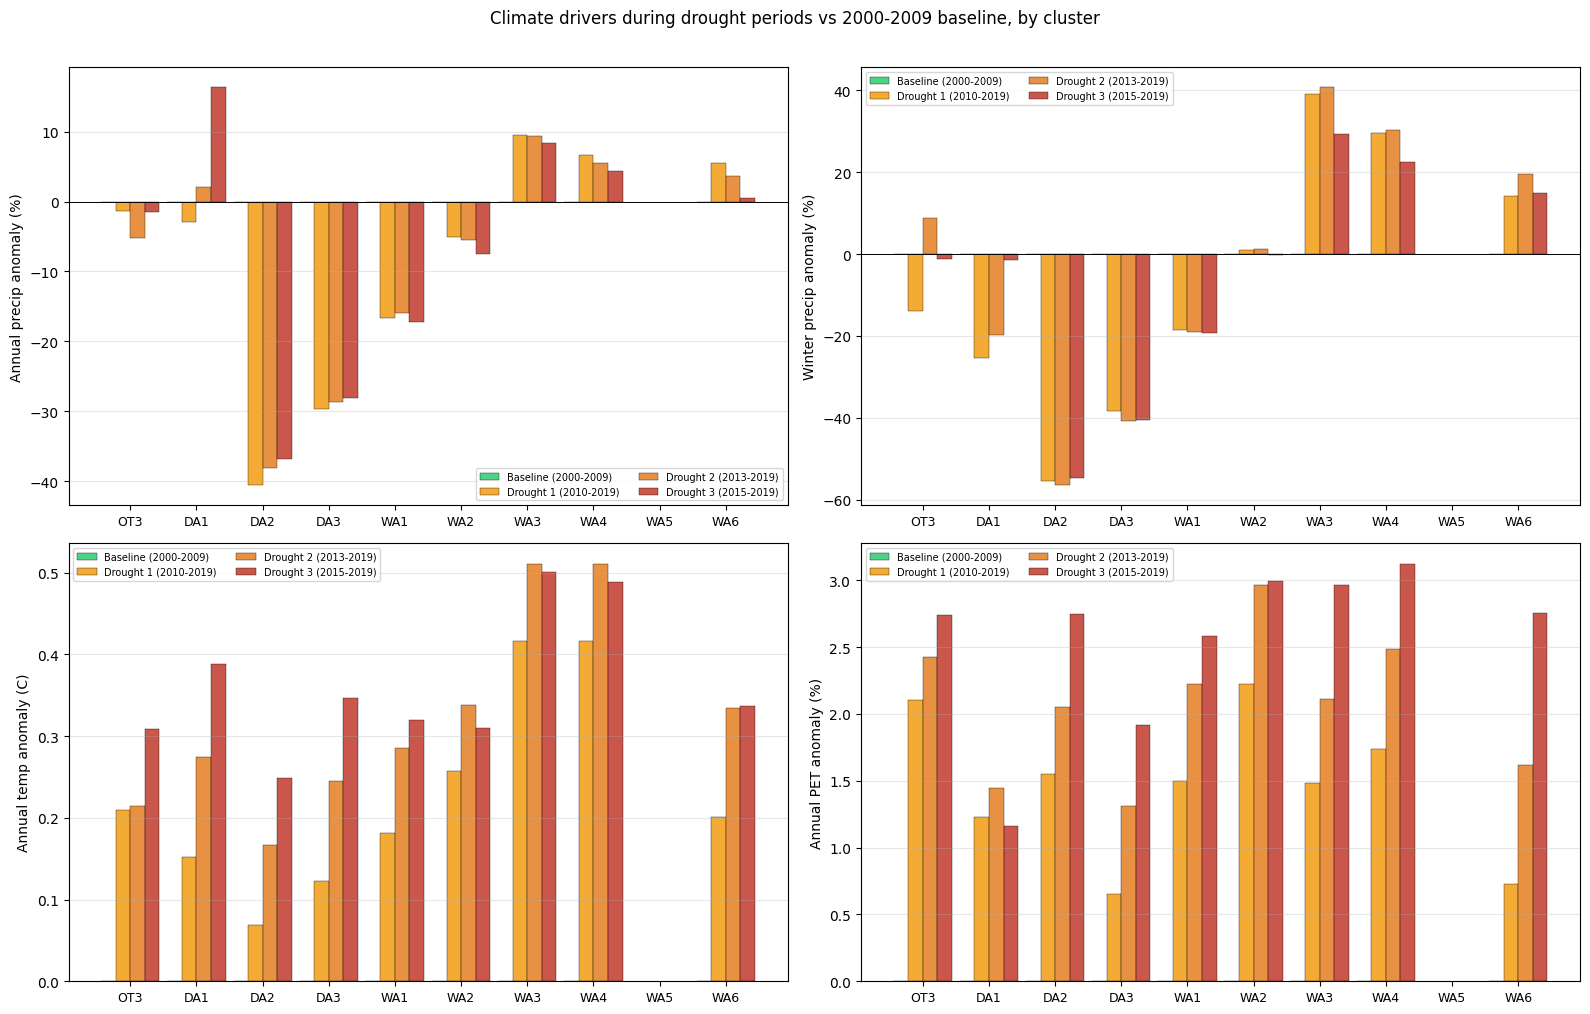

In [7]:
driver_records = []
for cl in CLUSTERS:
    cl_df = df_clim[df_clim['cluster'] == cl].set_index('year')
    for period_label, years in DROUGHT_DEFS.items():
        period_df = cl_df[cl_df.index.isin(years)]
        driver_records.append({
            'cluster': cl, 'period': period_label,
            'precip_ann_anom': period_df['precip_ann_anom_pct'].mean(),
            'precip_win_anom': period_df['precip_win_anom_pct'].mean(),
            'tmean_anom':      period_df['tmean_anom'].mean(),
            'pet_anom_pct':    period_df['pet_anom_pct'].mean(),
        })

df_drivers = pd.DataFrame(driver_records)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
driver_vars = [
    ('precip_ann_anom', 'Annual precip anomaly (%)'), ('precip_win_anom', 'Winter precip anomaly (%)'),
    ('tmean_anom', 'Annual temp anomaly (C)'), ('pet_anom_pct', 'Annual PET anomaly (%)'),
]

x = np.arange(len(CLUSTERS))
width = 0.22
offsets = [-1.5*width, -0.5*width, 0.5*width, 1.5*width]

for ax, (var, ylabel) in zip(axes.flatten(), driver_vars):
    for i, (period_label, years) in enumerate(list(DROUGHT_DEFS.items())):
        vals = []
        for cl in CLUSTERS:
            sub = df_drivers[(df_drivers['cluster'] == cl) & (df_drivers['period'] == period_label)]
            vals.append(sub[var].values[0] if len(sub) else np.nan)
        ax.bar(x + offsets[i], vals, width, label=period_label, color=DROUGHT_COLORS[period_label], alpha=0.85, edgecolor='k', lw=0.3)
    ax.axhline(0, color='k', lw=0.7)
    ax.set_xticks(x); ax.set_xticklabels(CLUSTERS, fontsize=9)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.legend(fontsize=7, ncol=2)

fig.suptitle('Climate drivers during drought periods vs 2000-2009 baseline, by cluster', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/climate_drivers_by_period_cluster.png', dpi=150, bbox_inches='tight')
plt.show()


## VII. Chile map (all_glacierized) + basin-set comparison figure

The spatial map shows the `all_glacierized` basin set (broadest
coverage). The comparison figure alongside it shows how the
amplification factor and decomposition vary across all three basin
sets and all three datasets, computed in Sections IV-V above.

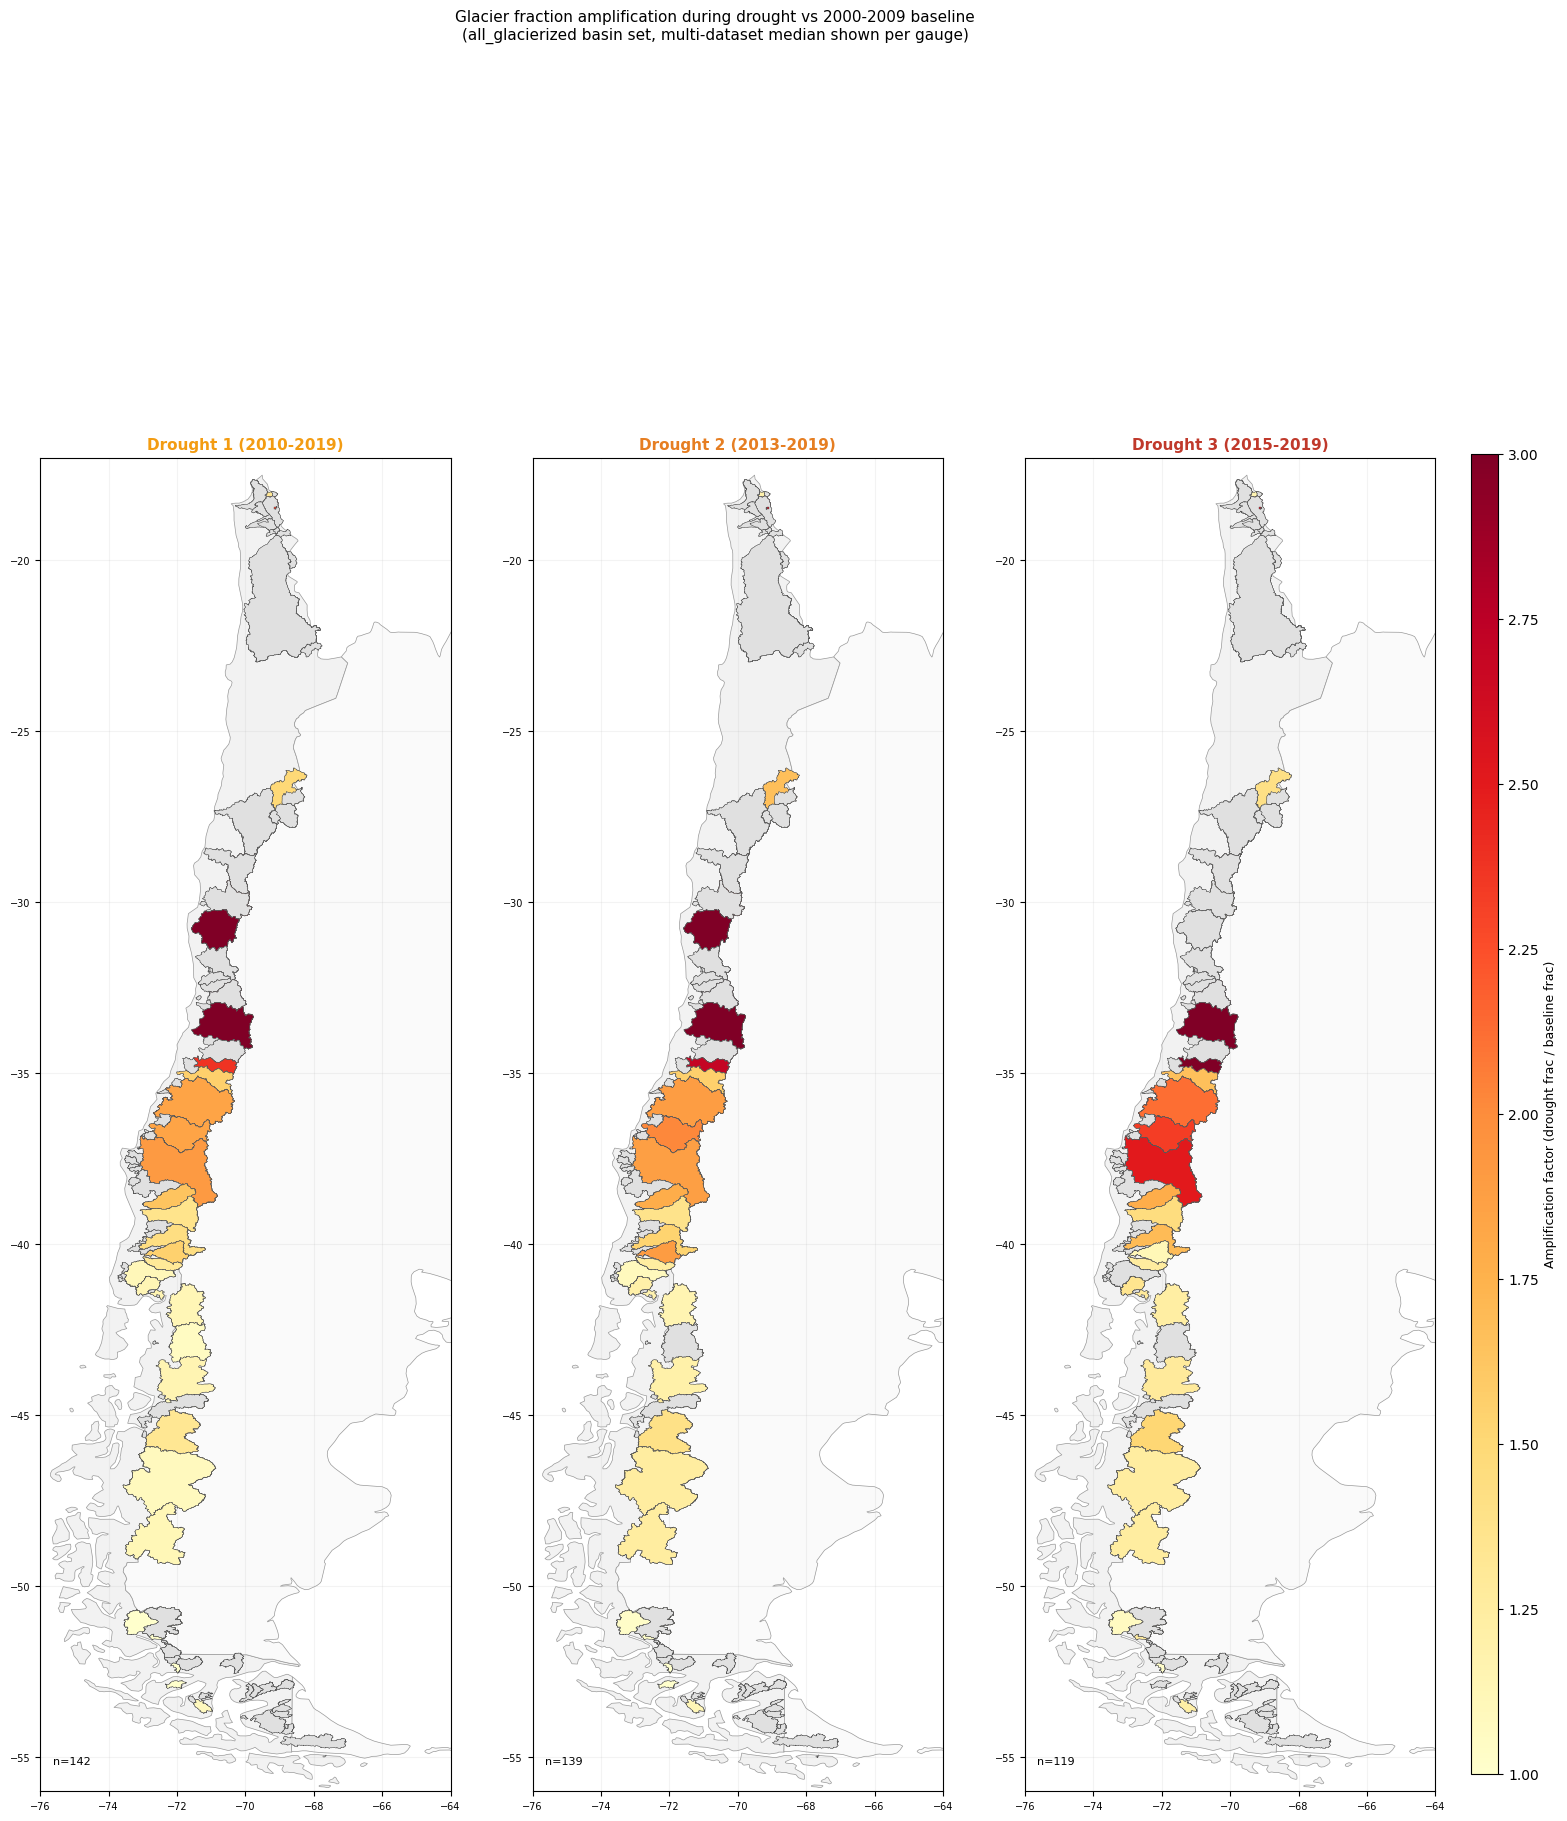

In [8]:
bounds = gpd.read_file(BOUNDS_PATH)
bounds['gauge_id'] = bounds['gauge_id'].astype(str)

try:
    world = gpd.read_file('https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip')
    chile = world[world['NAME'] == 'Chile']
    arg   = world[world['NAME'] == 'Argentina']
    has_borders = True
except Exception:
    has_borders = False

amp_mean = (df_periods[df_periods['amp_factor'].between(0, 10)]
            .groupby(['gauge_id','period'])['amp_factor'].median().reset_index()
            .rename(columns={'amp_factor': 'amp_med'}))

drought_periods = list(DROUGHT_DEFS.keys())[1:]
fig, axes = plt.subplots(1, 3, figsize=(18, 22))

from matplotlib.colors import Normalize, to_hex
from matplotlib.cm import ScalarMappable

cmap_amp = plt.cm.YlOrRd
norm_amp = Normalize(vmin=1.0, vmax=3.0)

for ax, period_label in zip(axes, drought_periods):
    if has_borders:
        chile.plot(ax=ax, facecolor='#f2f2f2', edgecolor='#999999', linewidth=0.5, zorder=0)
        arg.plot(ax=ax, facecolor='#fafafa', edgecolor='#999999', linewidth=0.5, zorder=0)
    bounds.plot(ax=ax, facecolor='#e0e0e0', edgecolor='#cccccc', linewidth=0.2, zorder=1)

    period_amp = amp_mean[amp_mean['period'] == period_label]
    bounds_plot = bounds.merge(period_amp[['gauge_id','amp_med']], on='gauge_id', how='left')
    face_colors = [to_hex(cmap_amp(norm_amp(v))) if not np.isnan(v) else '#e0e0e0' for v in bounds_plot['amp_med'].values]
    bounds_plot.plot(ax=ax, color=face_colors, edgecolor='#555555', linewidth=0.3, zorder=2)

    ax.set_xlim(-76, -64); ax.set_ylim(-56, -17); ax.set_aspect('equal')
    ax.tick_params(labelsize=7); ax.grid(True, alpha=0.15)
    ax.set_title(period_label, fontsize=11, fontweight='bold', color=DROUGHT_COLORS[period_label])
    n_valid = period_amp['amp_med'].notna().sum()
    ax.text(0.03, 0.02, f'n={n_valid}', transform=ax.transAxes, fontsize=8)

sm = ScalarMappable(cmap=cmap_amp, norm=norm_amp); sm.set_array([])
cbar_ax = fig.add_axes([0.92, 0.2, 0.015, 0.6])
cb = fig.colorbar(sm, cax=cbar_ax)
cb.set_label('Amplification factor (drought frac / baseline frac)', fontsize=9)

fig.suptitle('Glacier fraction amplification during drought vs 2000-2009 baseline\n'
             '(all_glacierized basin set, multi-dataset median shown per gauge)', fontsize=11, y=1.002)
plt.savefig(f'{DROUGHT_DIR}/drought_amplification_map.png', dpi=150, bbox_inches='tight')
plt.show()


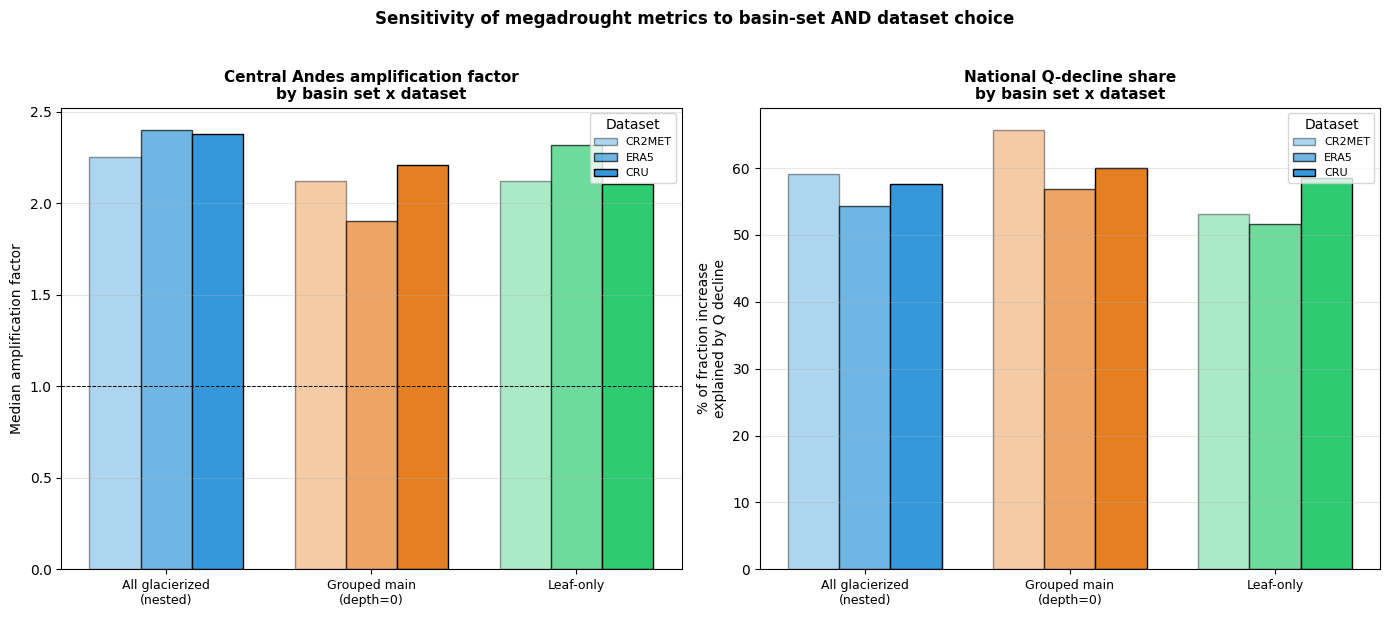

Saved: /Users/milliespencer/Desktop/CR2_OGGM_Paper/Output/megadrought_analysis/all_basin_sets/basin_set_dataset_comparison.png


In [9]:
# ── Basin-set x dataset comparison figure ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

basin_sets_order = BASIN_SET_NAMES
bs_colors = {'all_glacierized': '#3498db', 'grouped_main': '#e67e22', 'leaf_only': '#2ecc71'}
bs_labels = {'all_glacierized': 'All glacierized\n(nested)', 'grouped_main': 'Grouped main\n(depth=0)', 'leaf_only': 'Leaf-only'}

x = np.arange(len(basin_sets_order))
w = 0.25

ax = axes[0]
for j, ds_name in enumerate(['CR2MET', 'ERA5', 'CRU']):
    vals = []
    for bs_name in basin_sets_order:
        sub = df_periods_all[
            (df_periods_all['basin_set'] == bs_name) & (df_periods_all['dataset'] == ds_name) &
            (df_periods_all['period'] == 'Drought 1 (2010-2019)') &
            (df_periods_all['cluster'].isin(CENTRAL_ANDES)) &
            (df_periods_all['amp_factor'].notna()) & (df_periods_all['amp_factor'] < 10)]
        vals.append(sub['amp_factor'].median() if len(sub) else np.nan)
    offs = (j - 1) * w
    ax.bar(x + offs, vals, w, color=[bs_colors[bs] for bs in basin_sets_order], alpha=0.4+0.3*j, edgecolor='k', label=ds_name)
ax.set_xticks(x); ax.set_xticklabels([bs_labels[bs] for bs in basin_sets_order], fontsize=9)
ax.set_ylabel('Median amplification factor', fontsize=10)
ax.set_title('Central Andes amplification factor\nby basin set x dataset', fontsize=11, fontweight='bold')
ax.axhline(1.0, color='k', lw=0.7, ls='--')
ax.legend(fontsize=8, title='Dataset')
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
for j, ds_name in enumerate(['CR2MET', 'ERA5', 'CRU']):
    vals = []
    for bs_name in basin_sets_order:
        sub = df_decomp_all[
            (df_decomp_all['basin_set'] == bs_name) & (df_decomp_all['dataset'] == ds_name) &
            (df_decomp_all['delta_frac'] > 0)]
        vals.append(sub['pct_q_decline'].median() if len(sub) else np.nan)
    offs = (j - 1) * w
    ax.bar(x + offs, vals, w, color=[bs_colors[bs] for bs in basin_sets_order], alpha=0.4+0.3*j, edgecolor='k', label=ds_name)
ax.set_xticks(x); ax.set_xticklabels([bs_labels[bs] for bs in basin_sets_order], fontsize=9)
ax.set_ylabel('% of fraction increase\nexplained by Q decline', fontsize=10)
ax.set_title('National Q-decline share\nby basin set x dataset', fontsize=11, fontweight='bold')
ax.legend(fontsize=8, title='Dataset')
ax.grid(True, alpha=0.3, axis='y')

fig.suptitle('Sensitivity of megadrought metrics to basin-set AND dataset choice', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{DROUGHT_DIR}/basin_set_dataset_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {DROUGHT_DIR}/basin_set_dataset_comparison.png')


## VIII. Summary of findings

**1. Empirical validation of drought period definitions**

The megadrought was not a Chile-wide phenomenon. Precipitation deficits
concentrated in central/northern Chile (DA2: -37 to -40%, DA3: -28 to
-30%, WA1: -16 to -17%), while Patagonia (WA3, WA4, WA6) received
above-normal precipitation over the same periods -- consistent with
Garreaud et al. (2020)'s characterization of this as a central-Chile
event.

**2. Snow drought classification**

Two distinct mechanisms: dry snow drought (DA1, DA2, DA3, WA1) and warm
snow drought (WA2, WA3, WA4, WA6). DA3 and WA1 transitioned from dry to
compound (dry+warm) by 2015-2019.

**3. Glacier fraction amplification and decomposition -- basin-set and
dataset dependence**

Sections IV, V, and VII (comparison figure) show these numbers directly
depend on both basin-set choice and climate dataset -- see the printed
tables and the basin-set comparison figure above for the actual
sensitivity, rather than a single headline number. Use those tables when
deciding what to report to co-authors and in the paper, rather than
citing one basin-set/dataset combination in isolation.

**4. Climate drivers**

Temperature anomalies during drought were modest (+0.07 to +0.42C)
compared to precipitation deficits (-55% in DA2). Precipitation decline
is the dominant driver of drought amplification in central Chile.

### Pending analyses (continued in 06_megadrought_extensions.ipynb)

- Peak water analysis, recession/routing (Becca), basin aridity (Becca),
  mu_star comparison (Ale), seasonal-definition question, corrected WA1
  lag analysis, long-term melt/mass-balance trends and the "bank
  account" hypothesis (Noah), and methods-draft statistics (Ale).


## Verification pass: re-checking headline claims across all 9 combinations

Directly tests, for every basin-set x dataset combination, the
"significant increasing glacier-fraction trend" share and the
Q-decline/melt-change decomposition -- closing the loop on the
discrepancy between originally-reported figures and what a rerun
produces, within this notebook itself (rather than needing a separate
`basin_set_comparison.ipynb` run).

In [10]:
from scipy.stats import linregress

print('Testing for significant increasing trend in glacier fraction, 2000-2019')
print('per basin, across all basin sets and datasets')
print('='*80)

frac_trend_records = []

for bs_name, bs_data in BASIN_SETS.items():
    RESULTS_bs, GAUGE_INFO_FRAC_bs = bs_data['RESULTS'], bs_data['GAUGE_INFO_FRAC']

    for gauge_id, info in GAUGE_INFO_FRAC_bs.items():
        cy = info['complete_years']
        cluster = info['clusters'][0] if info.get('clusters') else 'unknown'

        for ds_name in ['CR2MET', 'ERA5', 'CRU']:
            res = RESULTS_bs[ds_name].get(gauge_id)
            if res is None:
                continue
            m = res['monthly']
            mc = m[m['year'].isin(cy)]

            ann = mc.groupby('year').agg(glac_m3=('glacier_runoff_m3', 'sum'), q_m3=('q_m3_mon', 'sum')).reset_index()
            ann = ann[ann['q_m3'] > 0]
            if len(ann) < 10:
                continue

            ann['frac'] = ann['glac_m3'] / ann['q_m3']
            slope, intercept, r, p, se = linregress(ann['year'].values, ann['frac'].values)

            frac_trend_records.append({
                'basin_set': bs_name, 'gauge_id': gauge_id, 'cluster': cluster, 'dataset': ds_name,
                'sig_increase': (p < 0.05) and (slope > 0), 'sig_decrease': (p < 0.05) and (slope < 0)})

df_frac_trend_all = pd.DataFrame(frac_trend_records)
df_frac_trend_all.to_csv(f'{DROUGHT_DIR}/glacier_fraction_trend_verification_all.csv', index=False)

print('National: % of basins with significant INCREASING glacier fraction, by basin set x dataset')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_frac_trend_all[(df_frac_trend_all['basin_set'] == bs_name) & (df_frac_trend_all['dataset'] == ds_name)]
        pct = sub['sig_increase'].mean() * 100 if len(sub) else np.nan
        row += f' {pct:9.1f}%'
    print(row)

print()
print('Central Andes: % of basins with significant INCREASING trend, by basin set x dataset')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_frac_trend_all[
            (df_frac_trend_all['basin_set'] == bs_name) & (df_frac_trend_all['dataset'] == ds_name) &
            (df_frac_trend_all['cluster'].isin(CENTRAL_ANDES))]
        pct = sub['sig_increase'].mean() * 100 if len(sub) else np.nan
        row += f' {pct:9.1f}%'
    print(row)


Testing for significant increasing trend in glacier fraction, 2000-2019
per basin, across all basin sets and datasets
National: % of basins with significant INCREASING glacier fraction, by basin set x dataset
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized         51.8%      54.6%      54.6%
grouped_main            50.0%      53.1%      50.0%
leaf_only               42.6%      46.3%      44.4%

Central Andes: % of basins with significant INCREASING trend, by basin set x dataset
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized         72.0%      56.0%      62.0%
grouped_main            88.9%      77.8%      77.8%
leaf_only               68.8%      50.0%      62.5%


In [11]:
print('Max amplification factor (Drought 1 vs baseline), by basin set x dataset:')
print(f'{"Basin set":18s} {"CR2MET":10s} {"ERA5":10s} {"CRU":10s}')
print('-' * 50)
for bs_name in BASIN_SET_NAMES:
    row = f'{bs_name:18s}'
    for ds_name in ['CR2MET', 'ERA5', 'CRU']:
        sub = df_periods_all[
            (df_periods_all['basin_set'] == bs_name) & (df_periods_all['dataset'] == ds_name) &
            (df_periods_all['period'] == 'Drought 1 (2010-2019)') & (df_periods_all['cluster'].isin(CENTRAL_ANDES))]
        mx = sub['amp_factor'].max() if len(sub) else np.nan
        row += f' {mx:9.2f}x'
    print(row)

import scipy.stats as ss
sub_cr2_all = df_periods_all[
    (df_periods_all['basin_set'] == 'all_glacierized') & (df_periods_all['dataset'] == 'CR2MET') &
    (df_periods_all['period'] == 'Drought 1 (2010-2019)') & (df_periods_all['cluster'].isin(CENTRAL_ANDES))]
if len(sub_cr2_all):
    pct = ss.percentileofscore(sub_cr2_all['amp_factor'].dropna(), 3.7)
    print(f'\n3.7x (the originally-reported figure) falls at the {pct:.0f}th percentile of')
    print(f'Central Andes amp_factor under all_glacierized/CR2MET.')

print()
print('CONCLUSION: compare the tables above (and the comparison figure in Section VII)')
print('across rows (basin set) and columns (dataset) to see which choice drives the')
print('gap between originally-reported figures and this rerun. Bring this comparison')
print('to the co-author discussion on which basin definition to standardize on.')


Max amplification factor (Drought 1 vs baseline), by basin set x dataset:
Basin set          CR2MET     ERA5       CRU       
--------------------------------------------------
all_glacierized         6.68x      8.40x     10.69x
grouped_main            3.70x      3.65x      3.99x
leaf_only               4.49x      5.13x      4.78x

3.7x (the originally-reported figure) falls at the 82th percentile of
Central Andes amp_factor under all_glacierized/CR2MET.

CONCLUSION: compare the tables above (and the comparison figure in Section VII)
across rows (basin set) and columns (dataset) to see which choice drives the
gap between originally-reported figures and this rerun. Bring this comparison
to the co-author discussion on which basin definition to standardize on.
